In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect("store2.db")
con.execute("DROP TABLE IF EXISTS customers")
con.execute("""
CREATE TABLE customers (
id INTEGER PRIMARY KEY,
name TEXT,
city TEXT,
balance REAL
)
""")
con.execute("""
INSERT INTO customers (id, name, city, balance) VALUES
(1, 'Joe Budden', 'Austin', 1250.50),
(2, 'Ben Simmons', 'Denver', 830.00),
(3, 'Jeremy Lin', 'Seattle', 2175.25),
(4, 'Jahlil Okafor', 'Chicago', 410.75),
(5, 'Goran Dragic', 'Boston', 1980.00),
(6, 'Hassan Whiteside', 'Miami', 95.40),
(7, 'Damian Mccullom', 'Portland', 3020.10),
(8, 'Devin Paul', 'Phoenix', 560.00),
(9, 'Nickeil Walker', 'Atlanta', 1445.90)

""")
con.commit()

In [3]:
pd.read_sql("SELECT * FROM customers WHERE balance > 1000", con)

,id,name,city,balance
0,1,Joe Budden,Austin,1250.50
1,3,Jeremy Lin,Seattle,2175.25
2,5,Goran Dragic,Boston,1980.00
3,7,Damian Mccullom,Portland,3020.10
4,9,Nickeil Walker,Atlanta,1445.90


In [4]:
pd.read_sql("SELECT name, city, balance FROM customers ORDER BY balance DESC", con)

,name,city,balance
0,Damian Mccullom,Portland,3020.10
1,Jeremy Lin,Seattle,2175.25
2,Goran Dragic,Boston,1980.00
3,Nickeil Walker,Atlanta,1445.90
4,Joe Budden,Austin,1250.50
5,Ben Simmons,Denver,830.00
6,Devin Paul,Phoenix,560.00
7,Jahlil Okafor,Chicago,410.75
8,Hassan Whiteside,Miami,95.40


In [5]:
pd.read_sql("SELECT * FROM customers WHERE name LIKE '%an%'", con)

,id,name,city,balance
0,5,Goran Dragic,Boston,1980.0
1,6,Hassan Whiteside,Miami,95.4
2,7,Damian Mccullom,Portland,3020.1


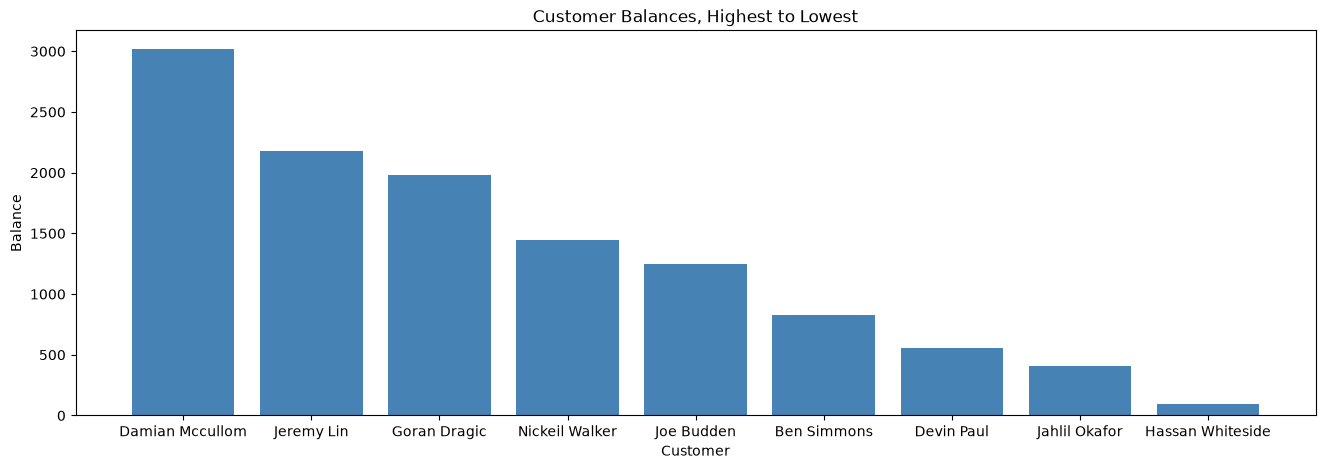

In [10]:
df = pd.read_sql("SELECT name, balance FROM customers ORDER BY balance DESC", con)

plt.figure(figsize=(16, 5))
plt.bar(df["name"], df["balance"], color="steelblue")
plt.title("Customer Balances, Highest to Lowest")
plt.xlabel("Customer")
plt.ylabel("Balance")
plt.show()